# Voting Regressor

Combine the Linear Regression and KNN models by averaging their predictions.

In [19]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

## Load the preprocessed data

In [20]:
X_train = pd.read_csv('data/X_train_pre.csv')
X_val   = pd.read_csv('data/X_val_pre.csv')
X_test  = pd.read_csv('data/X_test_pre.csv')
y_train = pd.read_csv('data/y_train.csv').squeeze('columns')
y_val   = pd.read_csv('data/y_val.csv').squeeze('columns')
y_test  = pd.read_csv('data/y_test.csv').squeeze('columns')

In [21]:
best_k, best_w = 3, 'uniform'   # best KNN settings from 03_knn_regressor.ipynb

linear_base = LinearRegression()
knn_base = KNeighborsRegressor(n_neighbors=best_k, weights=best_w)

## Build the Voting Regressor

In [22]:
voting_model = VotingRegressor(
    estimators=[
        ('lr', linear_base),
        ('knn', knn_base)
    ]
)

voting_model.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('knn', ...)]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[LinearRegression(), KNeighborsReg...n_neighbors=3)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,9
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'lr': Linear..._neighbors=3)}
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


## Compare on the validation set

In [23]:
linear_fit = LinearRegression().fit(X_train, y_train)
knn_fit = KNeighborsRegressor(n_neighbors=best_k, weights=best_w).fit(X_train, y_train)

val_preds = {
    'Linear Regression': linear_fit.predict(X_val),
    'KNN Regressor': knn_fit.predict(X_val),
    'Voting Regressor': voting_model.predict(X_val)
}

val_results = pd.DataFrame({
    'RMSE': {n: root_mean_squared_error(y_val, p) for n, p in val_preds.items()},
    'MAE':  {n: mean_absolute_error(y_val, p) for n, p in val_preds.items()},
    'R2':   {n: r2_score(y_val, p) for n, p in val_preds.items()},
})
val_results.index.name = 'Model'

display(val_results.round(3))

,RMSE,MAE,R2
Model,,,
Linear Regression,6316.682,4321.717,0.767
KNN Regressor,5940.316,3488.533,0.794
Voting Regressor,5795.390,3704.942,0.804


Correlation between Linear and KNN errors (validation): 0.784


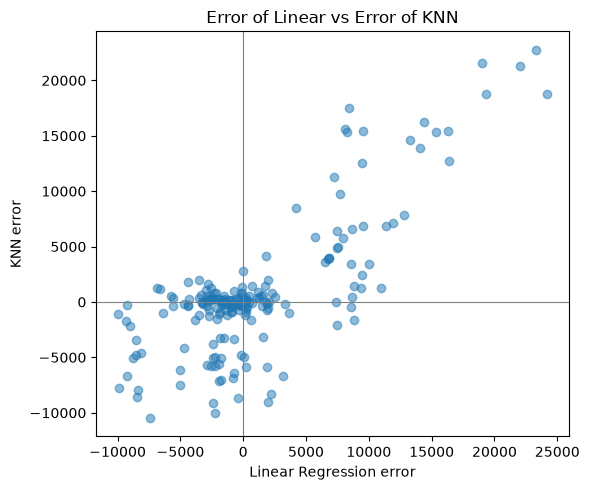

In [24]:
lin_err = np.ravel(y_val - val_preds['Linear Regression'])
knn_err = np.ravel(y_val - val_preds['KNN Regressor'])

error_corr = np.corrcoef(lin_err, knn_err)[0, 1]
print(f"Correlation between Linear and KNN errors (validation): {error_corr:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(lin_err, knn_err, alpha=0.5)
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlabel('Linear Regression error')
plt.ylabel('KNN error')
plt.title('Error of Linear vs Error of KNN')
plt.tight_layout()
plt.show()

## Final evaluation on the test set

In [25]:
test_preds = {
    'Linear Regression': linear_fit.predict(X_test),
    'KNN Regressor': knn_fit.predict(X_test),
    'Voting Regressor': voting_model.predict(X_test)
}

test_results = pd.DataFrame({
    'RMSE': {n: root_mean_squared_error(y_test, p) for n, p in test_preds.items()},
    'MAE':  {n: mean_absolute_error(y_test, p) for n, p in test_preds.items()},
    'R2':   {n: r2_score(y_test, p) for n, p in test_preds.items()},
})
test_results.index.name = 'Model'

display(test_results.round(3))

,RMSE,MAE,R2
Model,,,
Linear Regression,6162.781,4041.915,0.777
KNN Regressor,5901.323,3481.535,0.796
Voting Regressor,5675.696,3505.026,0.811


## Plotting the comparison

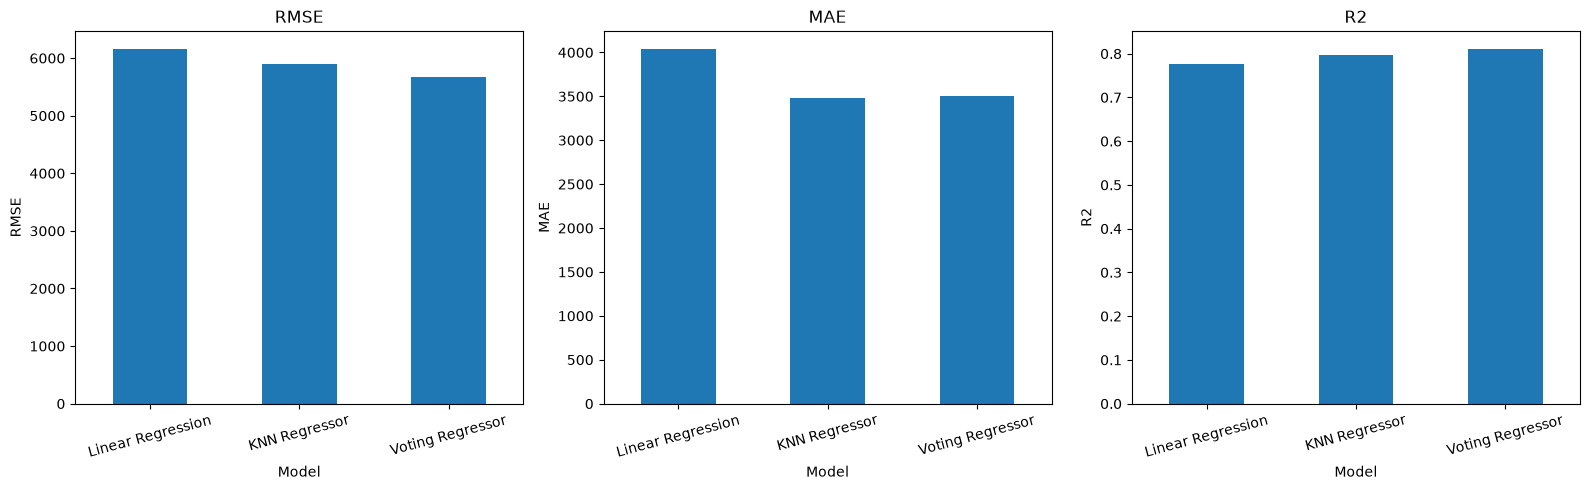

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
    test_results[metric].plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## Actual vs Predicted

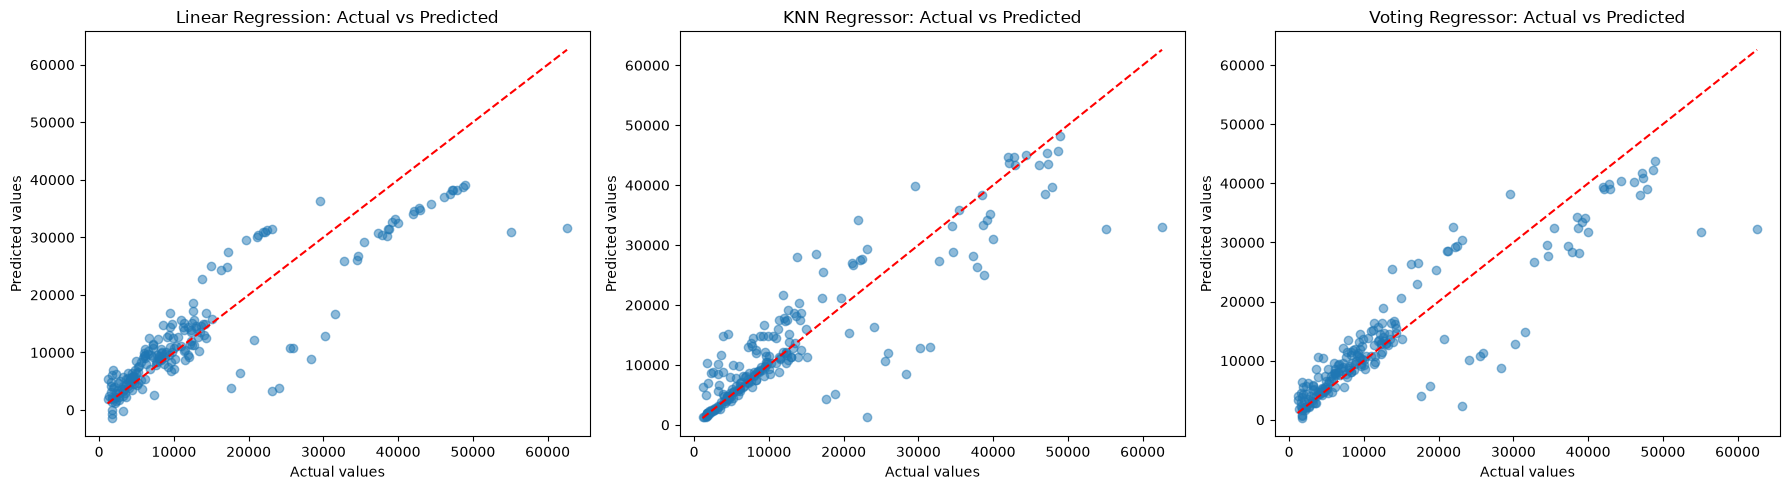

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, test_preds.items()):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )
    ax.set_xlabel('Actual values')
    ax.set_ylabel('Predicted values')
    ax.set_title(f'{name}: Actual vs Predicted')

plt.tight_layout()
plt.show()

## Residual comparison

Residual = Actual - Predicted. A distribution concentrated around zero is preferable.

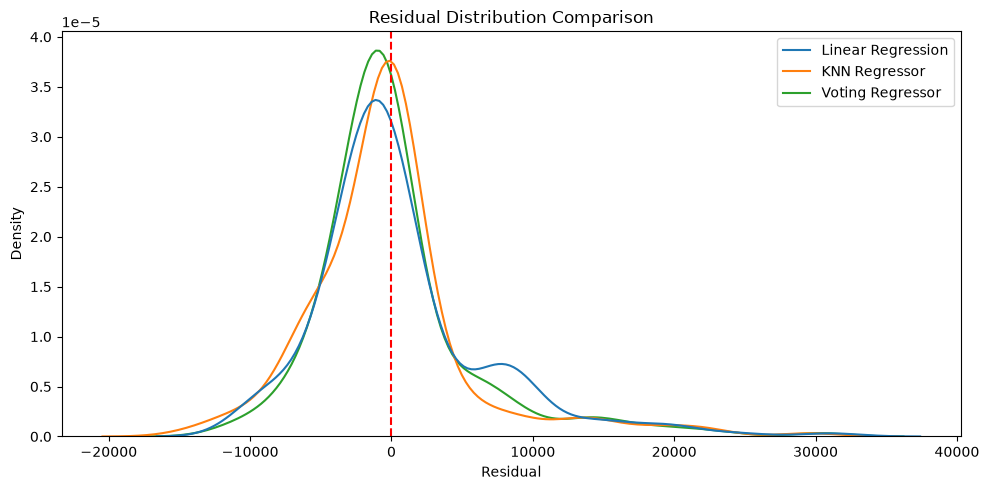

In [28]:
residuals = pd.DataFrame({
    name: y_test.values - np.ravel(pred) for name, pred in test_preds.items()
})

plt.figure(figsize=(10, 5))
sns.kdeplot(data=residuals, fill=False)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Residual')
plt.title('Residual Distribution Comparison')
plt.tight_layout()
plt.show()

## Best model

The model with the lowest test RMSE is selected. MAE and R² are also considered.

In [29]:
best_model_name = test_results['RMSE'].idxmin()

print("Best model based on test RMSE:", best_model_name)
display(test_results.sort_values('RMSE').round(3))

Best model based on test RMSE: Voting Regressor


,RMSE,MAE,R2
Model,,,
Voting Regressor,5675.696,3505.026,0.811
KNN Regressor,5901.323,3481.535,0.796
Linear Regression,6162.781,4041.915,0.777


## Save the Voting model

In [30]:
os.makedirs('../models', exist_ok=True)
joblib.dump(voting_model, '../models/voting_regressor.pkl')

['../models/voting_regressor.pkl']